# Práctica: Detección de anomalías a partir de sensores (CASAS scripted-ADL)
**Entornos Inteligentes · Grado en Inteligencia Artificial (UA)**

Dataset: *CASAS Smart Home - scripted activities, with and without activity errors* (Zenodo record [15712834](https://zenodo.org/records/15712834)).
Cita obligatoria: Cook, D. & Schmitter-Edgecombe, M. (2009). *Assessing the quality of activities in a smart environment*. Methods of Information in Medicine, 48(5), 480-485.

## ¿Qué escribís vosotros y qué viene ya fijado?

| Bloque | ¿Quién lo escribe? |
|---|---|
| Codificación de los CSV en el tensor fijo (carry-forward) | **Vosotros** (sección 4) |
| Al menos una arquitectura de detector (la elegís) | **Vosotros** (sección 7) |
| **Bucle de entrenamiento** (`train_model`: forward/loss/backward/optimizer) | **Vosotros** (sección 7) |
| Descargar el dataset | **FIJO** (sección 1, no se modifica) |
| Reparto de la validación: 5-fold CV **por participante** (sobre las 180 del pool), semilla 42 | **FIJO** (sección 6, no se modifica) |
| Pérdida, optimizador, hiperparámetros base, nº de épocas | **FIJOS** (secciones 6-7, no se modifican) |
| Métricas que se reportan (AUC, F1, precisión, recall, exactitud @0.5) | **FIJAS** (sección 6, no se modifican) |
| **Test conjunto de toda la clase**: 40 ejecuciones que **nadie entrena**; entreno final sobre las 180 y predicciones sobre las 40 | **FIJO** (sección 9, no se modifica) |
| Formato de la tabla de resultados | **FIJO** (sección 8) |

> Las celdas marcadas con **[FIJO - NO MODIFICAR]** no se tocan: todos los equipos usan el mismo reparto y las mismas métricas, así que los resultados son comparables. Lo que sí escribís vosotros es la **codificación del tensor** (sección 4), la **arquitectura** y el **bucle de entrenamiento** (sección 7).
>
> El **test conjunto** (40 ejecuciones sin etiqueta) es el mismo para todos y queda fuera de todo entrenamiento. Al final entrenáis una última vez sobre las 180 restantes y guardáis vuestras predicciones en `pred_test.json`: ese AUC sobre el test conjunto es la cifra que decide el ranking de la clase (sección 6 del enunciado).

## Distribución del tiempo (~8 h en clase + casa)
1. **Descargar los datos y explorar la anomalía en la señal** (~ 1,5 h): secciones 1-3.
2. **Codificar el tensor fijo** (~ 2,5 h): sección 4; la celda de validación comprueba sola vuestra codificación.
3. **Diseñar el detector y escribir vuestro bucle de entrenamiento** (~ 2 h en clase): sección 7.
4. **Evaluar con el protocolo fijo + empezar el informe** (~ 1,5 h): secciones 8-9 (la sección 9, el test conjunto, son ~ 5 min de código ejecutarse).
5. **En casa**: terminar el informe; opcional **+1**: ranking de >= 2 arquitecturas (sección 10).


## 0. Dependencias y arranque

Instala las dependencias una vez al principio. Si usáis GPU (Colab) el entrenamiento va ~20x más rápido; en CPU la validación completa (5 folds x 30 épocas) tarda ~ 1-10 min por arquitectura (los modelos son pequeños a propósito: 220 ejecuciones).

In [1]:
# Conduct the basic imports
import os
import re
import csv
import json
import glob
import time
import torch
import numpy as np
import pandas as pd
import torch.nn as nn
import matplotlib.pyplot as plt

# Select the device
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", DEVICE)

# Fixed params
N_CH = 30
T_BINS, BIN_S = 180, 5      # rejilla: 180 bins de 5 s = 15 min
EPOCHS, BS, LR, SEED = 30, 16, 1e-3, 42
torch.manual_seed(SEED); np.random.seed(SEED)

device: cuda


## 1. Descargar el dataset **[FIJO - NO MODIFICAR]**

Descarga y descomprime los dos sets de Zenodo directamente en `data/` (`data/adl_noerror/` con 120 CSV y `data/adl_error/` con 100 CSV). Es **idempotente**: si ya están los CSV, no vuelve a descargar. Ejecutadla al principio (o solo si habéis borrado `data/`).

In [2]:
import urllib.request, zipfile, os
ZENODO = "https://zenodo.org/records/15712834/files"   # record 15712834

def _count(d):
    try: return len([f for f in os.listdir(d) if f.endswith(".csv")])
    except FileNotFoundError: return 0

def download_if_missing(name, n_expected):
    out_dir = os.path.join("data", name)
    n = _count(out_dir)
    if n == n_expected:
        print(f"{name}: ya descargado ({n} csv) - se omite")
        return
    url = f"{ZENODO}/{name}.zip?download=1"
    z = os.path.join("data", name + ".zip")
    print(f"descargando {url} ...")
    urllib.request.urlretrieve(url, z)
    with zipfile.ZipFile(z) as zf:
        zf.extractall("data")
    os.remove(z)
    print(f"{name}: {_count(out_dir)} csv descargados")

os.makedirs("data", exist_ok=True)
download_if_missing("adl_noerror", 120)
download_if_missing("adl_error",   100)
print("dataset listo en data/")

descargando https://zenodo.org/records/15712834/files/adl_noerror.zip?download=1 ...
adl_noerror: 120 csv descargados
descargando https://zenodo.org/records/15712834/files/adl_error.zip?download=1 ...
adl_error: 100 csv descargados
dataset listo en data/


## 2. Los datos

220 ejecuciones, en dos sets:

* `adl_noerror` - 120 ejecuciones normales (24 por tarea).
* `adl_error` - 100 ejecuciones con un error scriptado (20 por tarea).

Cada ejecución es un CSV `pXX.tY.csv` (participante x tarea) con columnas `date, time, sensor, message`; cada fila es un evento.

| Tarea | Descripción | Error scriptado (la anomalía) |
|---|---|---|
| t1 - Llamar por teléfono | Ir al teléfono, buscar el número y llamar | Marca un número equivocado y debe volver a marcar |
| t2 - Lavarse las manos | Lavarse en el fregadero con jabón | **No cierra el grifo al terminar** |
| t3 - Cocinar | Cocinar avena siguiendo la receta | No apaga la hornilla tras cocinar |
| t4 - Comer | Lleva la comida y la medicación al comedor | No lleva el bote de medicación |
| t5 - Limpiar | Lavar los platos en el fregadero | No usa agua al lavar los platos |

La anomalía se manifiesta en la señal. Ejemplo: en t2 con error, el canal de nivel de agua (AD1-B) **no baja al final** porque el grifo se queda abierto. Esa "cola" es lo que el detector debe aprender a leer.

In [169]:
# Tensor de REFERENCIA (solo para la validación de vuestra codificación) + etiquetas
REF = json.load(open("data/meta.json"))
X_ref = np.load("data/X_ref.npy")          # (220, 30, 180) float32
Y     = np.load("data/Y.npy")              # (220,) 0/1
print("X_ref:", X_ref.shape, X_ref.dtype, "| Y:", Y.shape,
      "| y=1 (error):", int(Y.sum()), "| y=0 (normal):", int((1-Y).sum()))
print("canales (orden FIJO, 30):", REF["channels"])

# TEST CONJUNTO de toda la clase (40 ejecuciones, SIN etiqueta; nadie entrena sobre él)
TEST_FILES = json.load(open("data/test_files.json"))["files"]
IDX_TEST = [i for i, r in enumerate(REF["runs"]) if r["file"] in TEST_FILES]
print(f"test conjunto: {len(IDX_TEST)} ejecuciones (el AUC sobre ellas decide el ranking de la clase)")

# Una ejecución cruda (con error)
df = pd.read_csv("data/adl_error/p17.t1.csv")
df.head(15)

X_ref: (220, 30, 180) float32 | Y: (220,) | y=1 (error): 100 | y=0 (normal): 120
canales (orden FIJO, 30): ['M01', 'M06', 'M07', 'M08', 'M09', 'M10', 'M13', 'M14', 'M15', 'M16', 'M17', 'M18', 'M21', 'M22', 'M23', 'I01', 'I02', 'I03', 'I04', 'I05', 'I06', 'I07', 'I08', 'I09', 'D01', 'asterisk', 'AD1-A', 'AD1-B', 'AD1-C', 'E01']
test conjunto: 40 ejecuciones (el AUC sobre ellas decide el ranking de la clase)


,date,time,sensor,message
0,2008-03-28,13:39:01.470516,M01,ON
1,2008-03-28,13:39:01.470516,M23,ON
2,2008-03-28,13:39:02.558202,M07,ON
3,2008-03-28,13:39:02.780142,M08,ON
4,2008-03-28,13:39:03.47996,M09,ON
5,2008-03-28,13:39:04.485779,M23,OFF
6,2008-03-28,13:39:04.485779,M07,OFF
7,2008-03-28,13:39:04.485779,M14,ON
8,2008-03-28,13:39:05.595804,M08,OFF
9,2008-03-28,13:39:06.345881,M09,OFF


## 3. Paso 1 - Explorar los datos y ver la anomalía (~ 1,5 h)

Tarea: elegid **una tarea** (p. ej. t2), tomad una ejecución **normal** (p50.t2) y una **con error** (p22.t2), y dibujad la señal cruda de ambas: movimiento (PIR) y nivel de agua (AD1-B). La figura debe dejar ver por qué el error es visible en la señal.

Preguntas para el informe: ¿qué sensores intervienen en la tarea elegida? ¿En qué zona temporal (bins) se ve la anomalía? ¿Y si la anomalía es la *ausencia* de algo (p. ej. t4, no llevar la medicación)?

### **3.1 Load the run**

In [ ]:
def load_run(name:str):
    """
        Lee un CSV pXX.tY.csv (nombre como 'p22.t2', sin extensión) y 
        devuelve un df ordenado con columnas: sensor, value (0/1 en discretos,
        nivel float en AD1-*), ts, t_bin.
    
    """
    # Get csv_s
    for d in ("adl_error", "adl_noerror"):
        p = os.path.join("data", d, name + ".csv")
        if os.path.exists(p):
            f = p; break
    # Preprocess data
    d = pd.read_csv(f)
    d["ts"] = pd.to_datetime(d["date"] + " " + d["time"], format="mixed")
    d = d.sort_values("ts").reset_index(drop=True)
    t0 = d["ts"].iloc[0]
    d["t_bin"] = ((d["ts"] - t0).dt.total_seconds() // BIN_S).astype(int)
    d["value"] = [float(m) if s.startswith("AD1") else
                  (1.0 if m in ("ON", "PRESENT", "OPEN", "START", "START_INSTRUCT") else 0.0)
                  for s, m in zip(d["sensor"], d["message"])]
    return d

In [181]:
# Load data
name_1 = 'p01.t2'
name_2 = 'p17.t2'
# Call the function
data1 = load_run(name_1)
data2 = load_run(name_2)

### **3.2 Plot Data**

In [180]:
def plot_pair(normal:str, error:str):
    """
        Dibuja la señal cruda de dos ejecuciones: PIR (área azul) + AD1-B (línea roja).
    """
    # Define the figure
    fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
    # Plot loop
    for ax, (name, lab, col) in zip(axes, [(normal, "NORMAL", "tab:blue"),
                                           (error, "CON ERROR", "tab:red")]):

        # Load data 
        d = load_run(name)
        # Get tap sensor data (sink water level)
        ad = d[d["sensor"] == "AD1-B"]
        if len(ad):
            # Plot step function --> t_bin (x) and value(integer)(y)
            # Keep value from detected bin to next
            ax.step(ad["t_bin"], ad["value"], where="post", color="tab:red", lw=2, label="AD1-B (agua)")
        # Get PIR data -> M* sensors
        pir = d[d["sensor"].str.startswith("M")]
        if len(pir):
            # X: time bins where people is detected
            ax.fill_between(pir["t_bin"], 1, 0, step="post", color=col, alpha=0.15, label="PIR (movimiento)")
        ax.set_title(f"{name} - {lab}", color=col)
        ax.set_ylim(-0.05, 1.15); ax.grid(alpha=0.3); ax.legend(loc="upper left", fontsize=8)
    axes[1].set_xlabel("tiempo desde el 1.er evento (bins de 5 s)")
    fig.tight_layout(); plt.show()



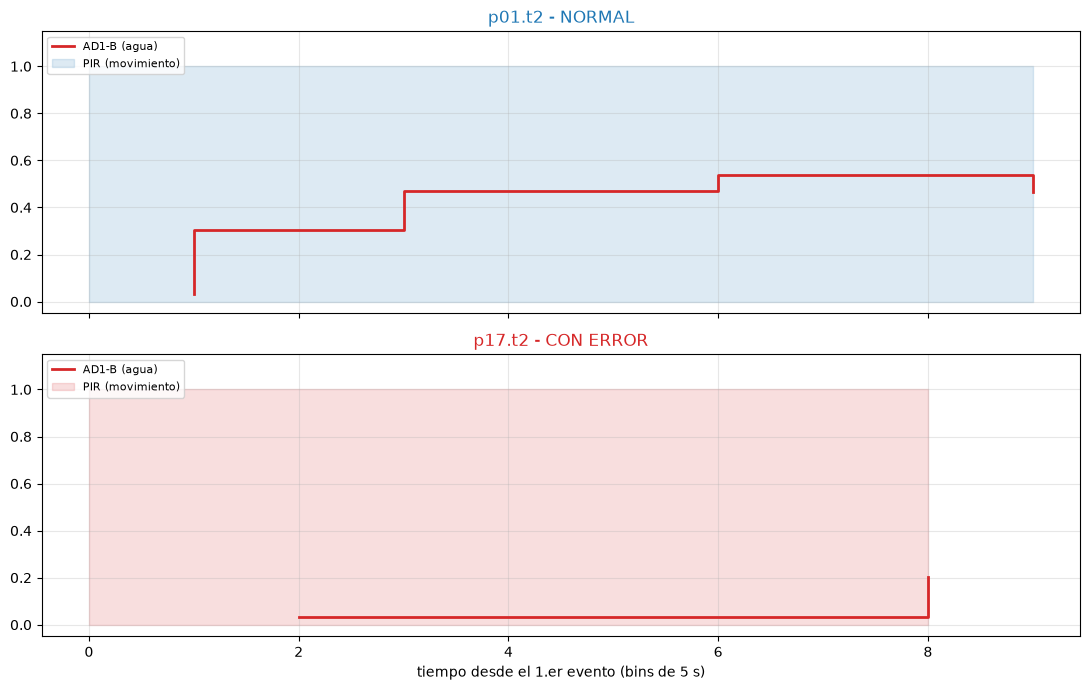

In [182]:
# Load data
name_1 = 'p01.t2'
name_2 = 'p17.t2'
# Ejemplo (cambiadlo por vuestra pareja):
plot_pair(name_1, name_2)

**¿Qué sensores intervienen en la tarea elegida? ¿En qué zona temporal (bins) se ve la anomalía?**

En el caso de la tarea seleccionada, t2 (lavado de manos), participan los sensores de la familia M0* que son los involucrados en la detección de movimiento y los pertenecientes al grupo AD1-[A,B], que están implicados en la lectura de un valor analógico asociado al nivel de agua del fregadero.


De manera relativa al csv **p17.t2**, que es depositario de la anomalía, podemos localizar que el comportamiento inusual se localiza en el último de los bins. En este caso concreto, el disparo de la alarma es dado por un nivel de caudal que no demuestra una tendencia decreciente hacia  el final de la secuencia, sino todo lo contrario; sugiriendo de esta manera que se ha dejado un grifo abierto.



In [ ]:
def plot_pair(normal:str, error:str, sensors:list[str]):
    """
        Dibuja la señal cruda de dos ejecuciones: PIR (área azul) + AD1-B (línea roja).
    """
    # Define the figure
    fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
    # Plot loop
    for ax, (name, lab, col) in zip(axes, [(normal, "NORMAL", "tab:blue"),
                                           (error, "CON ERROR", "tab:red")]):

        # Load data 
        d = load_run(name)
        # Get tap sensor data (sink water level)
        ad = d[d["sensor"] == "AD1-B"]
        if len(ad):
            # Plot step function --> t_bin (x) and value(integer)(y)
            # Keep value from detected bin to next
            ax.step(ad["t_bin"], ad["value"], where="post", color="tab:red", lw=2, label="AD1-B (agua)")
        # Get PIR data -> M* sensors
        pir = d[d["sensor"].str.startswith("M")]
        if len(pir):
            # X: time bins where people is detected
            ax.fill_between(pir["t_bin"], 1, 0, step="post", color=col, alpha=0.15, label="PIR (movimiento)")
        ax.set_title(f"{name} - {lab}", color=col)
        ax.set_ylim(-0.05, 1.15); ax.grid(alpha=0.3); ax.legend(loc="upper left", fontsize=8)
    axes[1].set_xlabel("tiempo desde el 1.er evento (bins de 5 s)")
    fig.tight_layout(); plt.show()



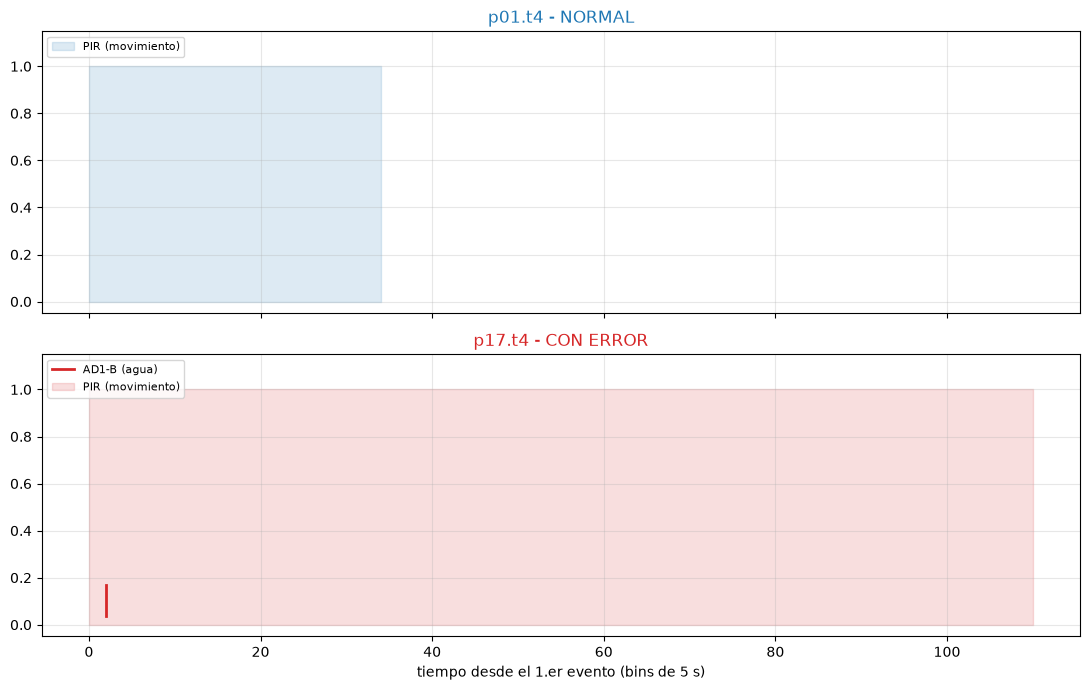

In [ ]:
# Load data
name_1 = 'p01.t4'
name_2 = 'p17.t4'
sensors = ["I06", ]
# Ejemplo (cambiadlo por vuestra pareja):
plot_pair(name_1, name_2)

**¿Y si la anomalía es la *ausencia* de algo (p. ej. t4, no llevar la medicación)?**



## 4. Paso 2 - Codificar el tensor fijo <- **vuestro código**

Cada ejecución se codifica en un tensor **(30 canales x 180 bins de 5 s)**, anclado al **primer evento**, con **carry-forward**: cada canal mantiene su último valor conocido hasta que llega un nuevo evento de ese sensor.

Reglas (las mismas que en el enunciado, sección 4):

* **Discretos** (M*, I*, D01, asterisk, E01): `1` mientras dura el estado activo (ON / PRESENT / OPEN / START..END / START_INSTRUCT..STOP_INSTRUCT), `0` en el estado contrario.
* **Analógicos** (AD1-A, AD1-B, AD1-C): el valor `message` tal cual (nivel), llevado al bin correspondiente.
* **Orden de canales FIJO** (30): el de la celda 2 (`REF["channels"]`).
* **Anclaje**: el 1.er evento de la ejecución cae en el bin 0. Los bins sin eventos mantienen el último valor conocido del canal (carry-forward); antes del primer evento de un sensor, su canal es 0.
* La normalización a [0,1] de los analógicos **la hace la celda fijada de la sección siguiente** (no la hagáis vosotros).

> El CSV de p22.t2 tiene 15 eventos en ~31 s, pero el tensor siempre mide 30 x 180. Solo 6 canales toman valores distintos de cero en esa ejecución.

Escribid `encode_run(path_csv) -> np.ndarray (30, 180)` float32.

### **USED CONSTANTS**

In [ ]:
# Fixed channel order
CH = REF["channels"]                       
CH_IDX = {s: i for i, s in enumerate(CH)}

# Assembly order
FILES = [f"data/{('adl_noerror' if r['set'] == 'noerror' else 'adl_error')}/{r['file']}"
         for r in REF["runs"]]


### **LOAD DATA**

In [5]:
def pd_loader(path = str)->pd.DataFrame:
    """  
        Function aimed to load csv data
        into a dataframe

        Params:
            path(str):
                The source path for  the csv file 

        Returns:
            df (pd.DataFrame):
                The returned dataFrame
    """
    # Load the pandas
    df = pd.read_csv(path)

    return df

In [6]:
# Check the loader behaviour
df = pd_loader('./data/adl_error/p59.t1.csv')

### **CLEANING DATA**

In [7]:
def mapping(sensor:str, message:str)->object:
    """ 
        Function aimed to map data

        Params:
            sensor(str):  
                The sensor to convert
            message(str):
                The raw sensor message

        Returns:
            output (object):
                The expected data type per sensor
    
    """
    # Define patterns and matchings
    patterns_list = {
                        'M(0[0-9]|1[0-9]|2[0-6])':{'ON':True},
                        "I[0][1-9]":{'PRESENT':True},
                        "D01":{"OPEN":True},
                        "asterisk":{"START":True},
                        "E[0][1]":{"START_INSTRUCT":True},
                        "AD1-[A-C]":None,

                    }

    # Look for matchings
    for pattern, values in patterns_list.items():
        # Get the slice for the key
        if re.fullmatch(pattern = pattern, string = sensor):
            # Switch continuous and discrete
            if values:
                # Handle  discrete ones
                return values.get(message, False)
            # Handle continuous
            try:
                return float(message)
            except ValueError:
                return None

In [8]:
def tester(title:str, chains:list[str], messages:list[str])->None:
    """     
        Function aimed to provide validation for the mapping 
        function 

        Params:
            title(str):
                The pattern to test
            chains(list[str]):
                The input chains 
            messages(list[str]):
                The input messages

        Returns:
            None:
                No value is returned
    """
    # Show title 
    print(f'\nTESTING ON PATTERN ({title})')
    for sensor, msg in zip(list_of_chains, list_of_messages):
        print(f'·Result Chain({sensor}-{msg}):', mapping(sensor, msg))

In [9]:

# Test group M01-M026
title = 'M01–M26'
list_of_chains = ["M01","M19", "M26", "M2", "M3"]
list_of_messages = ["OFF", 'ON', 'ON', 'ON', 'ON']
tester(title, list_of_chains, list_of_messages)


# Test group I01-I08
title = 'I01–I08'
list_of_chains = ["I01", "I08", "I18", "I19"]
list_of_messages = ["PRESENT", 'ABSENT', 'P', "O"]
tester(title, list_of_chains, list_of_messages)

# Test group D01
title = 'D01'
list_of_chains = ["D01", "D01", "D02"]
list_of_messages = ["OPEN", 'CLOSE', 'BAD']
tester(title, list_of_chains, list_of_messages)

# Test asterisk
title = 'asterisc'
list_of_chains = ["asterisc", "asterisco", " "]
list_of_messages = ["OPEN", 'CLOSE', 'BAD']
tester(title, list_of_chains, list_of_messages)

# Test AD1-A, AD1-B, AD1-C 
title = 'AD1-A, AD1-B, AD1-C'
list_of_chains = ["AD1-A", "AD1-B", "AD1-C"]
list_of_messages = [120.12, '12', '13']
tester(title, list_of_chains, list_of_messages)


# Test E01
title = 'E01'
list_of_chains = ["E01", "E01", "E01"]
list_of_messages = ["START_INSTRUCT", "STOP_INSTRUCT", "PASS"]
tester(title, list_of_chains, list_of_messages)




TESTING ON PATTERN (M01–M26)
·Result Chain(M01-OFF): False
·Result Chain(M19-ON): True
·Result Chain(M26-ON): True
·Result Chain(M2-ON): None
·Result Chain(M3-ON): None

TESTING ON PATTERN (I01–I08)
·Result Chain(I01-PRESENT): True
·Result Chain(I08-ABSENT): False
·Result Chain(I18-P): None
·Result Chain(I19-O): None

TESTING ON PATTERN (D01)
·Result Chain(D01-OPEN): True
·Result Chain(D01-CLOSE): False
·Result Chain(D02-BAD): None

TESTING ON PATTERN (asterisc)
·Result Chain(asterisc-OPEN): None
·Result Chain(asterisco-CLOSE): None
·Result Chain( -BAD): None

TESTING ON PATTERN (AD1-A, AD1-B, AD1-C)
·Result Chain(AD1-A-120.12): 120.12
·Result Chain(AD1-B-12): 12.0
·Result Chain(AD1-C-13): 13.0

TESTING ON PATTERN (E01)
·Result Chain(E01-START_INSTRUCT): True
·Result Chain(E01-STOP_INSTRUCT): False
·Result Chain(E01-PASS): False


In [118]:
def formatting_data(df:pd.DataFrame)->tuple[list, list, np.ndarray]:
    """  
        Function aimed to clean data given some 
        format requirements

        Params:
            df(pd.DataFrame):
                The input dataframe

        Returns:
            tuple: A tuple containing
                - date_n_time(list): A list containing date and time of reads in datetime format
                - switched_values(list): A list containing mapped messages
                - sensors_list(np.ndarray): Array containing  sensors' name
    """

    # Sort the values by date and time
    df = df.sort_values(by = ['date', 'time'])

    # Get the ordered list of sensors and its messages
    sensors_list = list(df.sensor.values)
    msg_list = list(df.message.values)
    print(f'·Sensors and messages\n{sensors_list}\n{msg_list}')
    # Get the right values for messages
    switched_values = [mapping(key, msg) for key, msg in zip(sensors_list, msg_list)]
    print(f'·Switched Values:{switched_values}')  

    # Put together date and time and set datetime format -> later substraction
    date_n_time = pd.to_datetime(df['date'] + ' ' + df['time'],
                                format = "mixed").to_list()
    print(f'·Datetime:{date_n_time}')  

    return date_n_time, np.array(sensors_list), switched_values

In [119]:
# Call the cleaning function
date_n_time, sensors_list, msg_data = formatting_data(df)

·Sensors and messages
['M01', 'M23', 'M07', 'M08', 'M09', 'M23', 'M07', 'M14', 'M08', 'M09', 'M13', 'M01', 'M14', 'M13', 'M13', 'M13', 'M13', 'M13', 'M13', 'M13', 'M13', 'M13', 'M13', 'M13', 'M13', 'M13', 'asterisk', 'M13', 'asterisk', 'M13']
['ON', 'ON', 'ON', 'ON', 'ON', 'OFF', 'OFF', 'ON', 'OFF', 'OFF', 'ON', 'OFF', 'OFF', 'ON', 'OFF', 'ON', 'OFF', 'ON', 'OFF', 'ON', 'OFF', 'ON', 'OFF', 'ON', 'OFF', 'ON', 'START', 'OFF', 'END', 'ON']
·Switched Values:[True, True, True, True, True, False, False, True, False, False, True, False, False, True, False, True, False, True, False, True, False, True, False, True, False, True, True, False, False, True]
·Datetime:[Timestamp('2008-03-28 13:39:01.470516'), Timestamp('2008-03-28 13:39:01.470516'), Timestamp('2008-03-28 13:39:02.558202'), Timestamp('2008-03-28 13:39:02.780142'), Timestamp('2008-03-28 13:39:03.479960'), Timestamp('2008-03-28 13:39:04.485779'), Timestamp('2008-03-28 13:39:04.485779'), Timestamp('2008-03-28 13:39:04.485779'), Timestam

### **GENERATE SHAPE**

In [67]:
def tensor_converter(data:list[object] )->torch.Tensor:
    """  
        Function aimed to convert the list provided
        into a tensor

        Params:
            data(list[object]):
                The list containing the data

        Returns:
            output(torch.Tensor):
                The created tensor  
    
    """

    # Create the tensor
    output = torch.tensor(data, dtype = torch.float)
    print(f'Shape of the Tensor({output.shape}) and dtype ({output.type()})')
    return output

In [68]:
# Load the reference
REF = json.load(open("data/meta.json"))

# Get the channels 
CH = REF['channels']

**BASE DISCRETIZATION**

In [79]:
def discretization(dates:list[pd.Timestamp] , sensors_list:np.ndarray, sensors_msgs:list[str], CH:list[str])->torch.Tensor:
    """  
        Function aimed to discretize data 
        into a given amount of bins. In case
        two reads should be belonging to the same
        bin, only the latest one is kept

        Params:
            dates(list(pd.Timestamp)):
                List containing the timestamp for each read
            sensors_list(np.ndarray):
                Array containing sensor's name
            sensors_msgs(list[object]):
                List containing sensor's messages

            CH(list[str]):
                List containing sensor's order
        Returns:

    
    """

    

    # GETTING DELTAS
    print('\nCOMPUTING DELTAS')
    # Get the first bin
    origin =  dates[0]
    print('·The anchor timestamp:', origin)
    # Get all timedeltas (deltas, )
    deltas = np.array(dates) - np.array(origin)
    print('·Aspect of the deltas:', deltas.shape, deltas.dtype)
    # From timestamp to seconds
    deltas = np.array([[delta.total_seconds()] for delta in deltas ])
    # Get seconds
    print('·Aspect of the deltas (seconds):', deltas.dtype, deltas.shape, list(deltas[:3]))

    # GETTING BIN FOR EACH DELTA
    print('\nCOMPUTING BINS')
    # Compute the hash -> set each delta to its cell
    hashing = deltas//BIN_S
    hashing = hashing.astype(np.int64).flatten()
    print('·Aspect of the hashing:', hashing.shape, hashing.dtype, list(hashing[:3]))

    # PAD THE REST OF THE MATRIX
    print('\nFILLING EACH CHANNEL')
    # Fullfill each channel
    channels = []
    CH = np.array(CH)
    # Iterate over channels    
    for channel in CH:
        # Create zeroed array (0*T_BINS)
        channel_storage = np.zeros(shape = (T_BINS))
        # Get matching indices -> sorted by timestamp (initial sorting)
        matching  = np.where(sensors_list ==  channel)[0]
        print(f'\nCH({channel})-->matchings:', matching)
        # Retrieve the bins --> [0, 0, 1, 2, 3, 4]-> i<=i+1
        bins = hashing[matching]
        print(f'·Retrieved bins:{bins.shape}{bins}')

        # Keep the leftmost bin values (latest ones) -> run from left to right -> latest to earliest
        unique = set(np.unique(bins))
        pairs = {uni:None for uni in unique}
        print(f'·Initial dictionary:', pairs)
        for idx_match, bin in zip(matching[::-1], bins[::-1]):
            #print(idx_match, bin)
            # No previously visited
            if pairs[bin] is None:
                # Register the index -> reverse
                pairs[bin] = idx_match
        print(f'·Bin commanders:', pairs)

        # Sort the dictionary -> not necessarry-> dict keeps the input order->latest to earliest bin
        # We need earliest to latest to make the algorithm work
        sorted_dict = dict(sorted(pairs.items()))
        #print(f'·Sorted dictionary:', sorted_dict)

        # Populate the list 
        print(f'·Populating bins')
        for key, value in sorted_dict.items():
            print('->Key and value:', key, value)
            # Retrieve data from current sensor
            state = sensors_msgs[value]
            print(f'->State:', state)
            # Each one will overlap adequately 
            # (000->)
            # (0001111111---->)
            # (00011111110000EOF>)
            channel_storage[key::] = state
            #print('Aspect of the storage:', channel_storage)

        print('·Final aspect of the channel:', channel_storage)

        # Append the channel
        channels.append(channel_storage)
        #print('Aspect of channels:', channels)

    # Generate the array (CH, Bins)
    channels = np.stack(channels)
    print('FINAL TENSOR:', channels.shape)

    return channels


In [80]:
# Discretize
discretization(date_n_time, sensors_list, msg_data, CH)


COMPUTING DELTAS
·The anchor timestamp: 2008-06-09 14:33:22.533578
·Aspect of the deltas: (28,) object
·Aspect of the deltas (seconds): float64 (28, 1) [array([0.]), array([0.]), array([0.795947])]

COMPUTING BINS
·Aspect of the hashing: (28,) int64 [np.int64(0), np.int64(0), np.int64(0)]

FILLING EACH CHANNEL

CH(M01)-->matchings: [1 7]
·Retrieved bins:(2,)[0 0]
·Initial dictionary: {np.int64(0): None}
·Bin commanders: {np.int64(0): np.int64(7)}
·Populating bins
->Key and value: 0 7
->State: False
·Final aspect of the channel: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0.

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]], shape=(30, 180))

**'FAST' DISCRETIZATION**

In [140]:
def fast_discretization(dates:list[pd.Timestamp] , sensors_list:np.ndarray, sensors_msgs:list[str], CH:list[str])->torch.Tensor:
    """  
        Function aimed to discretize data 
        into a given amount of bins. In case
        two reads should be belonging to the same
        bin, only the latest one is kept

        Params:
            dates(list(pd.Timestamp)):
                List containing the timestamp for each read
            sensors_list(np.ndarray):
                Array containing sensor's name
            sensors_msgs(list[object]):
                List containing sensor's messages

            CH(list[str]):
                List containing sensor's order
        Returns:
            output(np.array):
                Array of shape (channels, bins) representing
                that data per file

    
    """

    # Get the anchor time
    origin = dates[0]
    print('·The anchor timestamp:', origin)
    # Turn sensors into an array
    sensors_msgs = np.asarray(sensors_msgs)

    # Get all timedeltas (deltas, )
    print('GETTING DELTAS')
    deltas = np.array(dates) - np.array(origin)
    print('·Aspect of the deltas(timestamp):', deltas.shape, deltas.dtype, list(deltas[:3]))
    # From timestamp to seconds
    deltas = np.array([[delta.total_seconds()] for delta in deltas ])
    # Get seconds
    print('·Aspect of the deltas (seconds):',deltas.dtype, deltas.shape, list(deltas[:3]))

    # Compute the hash -> set each delta to its cell
    print('CALCULATING BINS')
    hashing = deltas//BIN_S
    hashing = hashing.astype(np.int64)
    print('·Aspect of the hashing:', hashing.shape, hashing.dtype, list(hashing[:3]))

    # Fullfill each channel
    print('POPULATING CHANNELS')
    channels = []
    for channel in CH:
        print(f'->CHANNEL({channel})')
        # Get matching indices -> sorted by timestamp (initial sorting)
        matching  = np.where(sensors_list ==  channel)[0]

        # Evaluate matching
        if matching.size == 0:
            channels.append(np.zeros(T_BINS))
            continue

        # Retrieve the bins --> [0, 0, 1, 2, 3, 4]
        bins = list(hashing[matching])
        print(f'·Retrieved bins:{bins}')

        # Get indices of first reversed (latest unique) appearences of data in each bin
        # Unique return sorted bins by value
        reversed_bins = bins[::-1]
        unique_bins, rev_bins = np.unique(reversed_bins, return_index = True)
        print(f'·Aspect of the unique bins:', unique_bins) 

        # Get sensor indices 
        bins_cmd_idx = matching[::-1][rev_bins]
        print(f'·Aspect of the bins unique commander indices:', bins_cmd_idx)

        # Get the sorted and unique per bin states
        states = sensors_msgs[bins_cmd_idx]
        # Create storage
        channel_storage = np.zeros(T_BINS)

        # Fill the storage
        for bin, state in zip(unique_bins, states):
            channel_storage[bin::] = state
        
        # Append the channel
        channels.append(channel_storage)
        print('·Aspect of the channel:', channel_storage)

    # Show the final tensor
    channels = np.stack(channels)
    print('\nAspect of the final channel:', channels.shape)
    return channels

In [117]:
# Discretize
fast_discretization(date_n_time, sensors_list, msg_data, CH)

·The anchor timestamp: 2008-06-09 14:33:22.533578
GETTING DELTAS
·Aspect of the deltas(timestamp): (28,) object [Timedelta('0 days 00:00:00'), Timedelta('0 days 00:00:00'), Timedelta('0 days 00:00:00.795947')]
·Aspect of the deltas (seconds): float64 (28, 1) [array([0.]), array([0.]), array([0.795947])]
CALCULATING BINS
·Aspect of the hashing: (28, 1) int64 [array([0]), array([0]), array([0])]
POPULATING CHANNELS
->CHANNEL(M01)
·Retrieved bins:[array([0]), array([0])]
·Aspect of the unique bins: [0]
·Aspect of the bins unique commander indices: [7]
·Aspect of the channel: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0

### **RETRIEVE FILES**

In [112]:
def retrieve_files(ref_runs:list[dict])->list[pd.DataFrame]:
    """ 
        Function aimed to generate the list of df
        to get the tensor from 

        Params:
            ref_runs(list(dict)):
                List defining the order of runs

        Returns:
            df_list(list[pd.DataFrame]):
                List of retrieved  dataframes
    """

    # Generate the paths
    paths = [f"data/{('adl_noerror' if r['set'] == 'noerror' else 'adl_error')}/{r['file']}"
         for r in REF["runs"]]

    # Generate the df
    df = [pd_loader(path) for path in paths]
    print('Amount of loaded files:', len(df))
    
    return df

In [125]:
# Call the function
df_list = retrieve_files(REF['runs'])

Amount of loaded files: 220


### **GENERATE BATCHES**

In [163]:
def encode_run(df_list:list[pd.DataFrame], CH:list[str])->np.ndarray:
    """  
        Function aimed to generated batches from a list 
        of dataframes. The steps are the following

        1. Convert messages to expected format and get deltas
        2. Fullfill all channels -> np.ndarray (channels, bins)
        3. Stack them into a array (files, channels, bins )
    
        Params:
            df_list(list(pd.DataFrame)):
                The list of collected dataframes
            CH(list[str]):
                The channel ordering

        Returns:
            output(np.ndarray):
                The output array of shape (files, channels, bins)
    """

    # Preprocess data
    mapped_data = [formatting_data(df) for df in df_list]

    # Build the array shape
    list_of_arrays = [fast_discretization(*data, CH = CH) for data in mapped_data]
    # Stack them to create (files, channels, bins)
    output = np.stack(list_of_arrays)
    print('Aspect of the final array:', output.shape)
    return output

In [167]:
# Call the function
X = encode_run(df_list, CH)

·Sensors and messages
['M01', 'M23', 'M07', 'M08', 'M09', 'M23', 'M07', 'M14', 'M08', 'M09', 'M13', 'M01', 'M14', 'M13', 'M13', 'M13', 'M13', 'M13', 'M13', 'M13', 'M13', 'M13', 'M13', 'M13', 'M13', 'M13', 'asterisk', 'M13', 'asterisk', 'M13']
['ON', 'ON', 'ON', 'ON', 'ON', 'OFF', 'OFF', 'ON', 'OFF', 'OFF', 'ON', 'OFF', 'OFF', 'ON', 'OFF', 'ON', 'OFF', 'ON', 'OFF', 'ON', 'OFF', 'ON', 'OFF', 'ON', 'OFF', 'ON', 'START', 'OFF', 'END', 'ON']
·Switched Values:[True, True, True, True, True, False, False, True, False, False, True, False, False, True, False, True, False, True, False, True, False, True, False, True, False, True, True, False, False, True]
·Datetime:[Timestamp('2008-03-28 13:39:01.470516'), Timestamp('2008-03-28 13:39:01.470516'), Timestamp('2008-03-28 13:39:02.558202'), Timestamp('2008-03-28 13:39:02.780142'), Timestamp('2008-03-28 13:39:03.479960'), Timestamp('2008-03-28 13:39:04.485779'), Timestamp('2008-03-28 13:39:04.485779'), Timestamp('2008-03-28 13:39:04.485779'), Timestam

## 5. Comprobación automática **[FIJO - NO MODIFICAR]**

Normaliza los analógicos como hace el protocolo (división por el máximo global de cada canal analógico) y compara vuestra `X` con el tensor de referencia. Debe imprimir **OK**. Si no pasa, la tabla os dice qué ejecuciones y qué canales difieren: los fallos típicos son el orden de ejecuciones, el orden de canales, el anclaje al primer evento o el carry-forward.

In [168]:
# ---- normalización FIJA (igual para todos) ----
def _normalize(X):
    X = X.astype(np.float32).copy()
    for s, c in CH_IDX.items():
        if s.startswith("AD1"):
            mx = X[:, c, :].max()
            if mx > 0:
                X[:, c, :] = X[:, c, :] / mx
    return X

Xn = _normalize(X)
ok = bool(np.allclose(Xn, X_ref, atol=1e-4))
if ok:
    print("VALIDACION CODIFICACION: OK - vuestra X coincide con la referencia")
else:
    diff = np.abs(Xn - X_ref) > 1e-4
    bad_runs = np.unique(np.where(diff.any(axis=(1, 2))[0]))
    bad_chs = np.unique(np.where(diff.any(axis=(0, 2))[0]))
    print("VALIDACION CODIFICACION: FALLO")
    print("ejecuciones que difieren (índice, nombre):",
          [(int(i), REF['runs'][i]['file']) for i in bad_runs[:10]],
          "…" if len(bad_runs) > 10 else "")
    print("canales que difieren:", [CH[i] for i in bad_chs[:10]],
          "…" if len(bad_chs) > 10 else "")
assert ok, 'La codificación no coincide con la referencia. Corregid encode_run y re-ejecutad.'

VALIDACION CODIFICACION: OK - vuestra X coincide con la referencia


## 6. Protocolo de validación y métricas **[FIJO - NO MODIFICAR]**

**Métricas fijas** (calculadas sobre las predicciones de la CV, agregadas entre folds; umbral 0.5 sobre la probabilidad de anomalía). Con la matriz de confusión (TP, FP, TN, FN):

| Métrica | Fórmula | Qué mide |
|---|---|---|
| **AUC (ROC)** - *principal* | P(puntuación(anomalía) > puntuación(normal)) | Calidad de la ordenación; independiente del umbral |
| F1 | 2·TP / (2·TP + FP + FN) | Equilibrio precisión/recall |
| Precisión | TP / (TP + FP) | Fracción de alarmas que son verdaderas |
| Recall | TP / (TP + FN) | Fracción de anomalías detectadas |
| Exactitud | (TP + TN) / total | Fracción global correcta (engañoza con desbalance) |

**Protocolo fijo**: 5-fold cross-validation **por participante** (ningún participante aparece a la vez en train y test), semilla 42, pérdida `BCEWithLogitsLoss` con `pos_weight = n_neg/n_pos` del fold, AdamW (lr=1e-3, wd=1e-4), cosine annealing, 30 épocas, batch 16. El AUC se reporta como **media ± desviación de los 5 folds**.

**Pool de entreno**: la CV se hace sobre las **180 ejecuciones del pool** (36 participantes). Las 40 del test conjunto de la clase (sección 9) quedan fuera de todo fold: así ningún equipo entrena, aunque sea por accidente, sobre las ejecuciones que se usan para el ranking final.

> **Nota de diseño:** esta celda fija el *reparto* (folds) y las *métricas*, pero **no** el bucle de entrenamiento. El bucle (forward/loss/backward/optimizer) lo escribís vosotros en la sección 7 (`train_model`); la función `train_eval` de abajo lo llama por cada fold con los hiperparámetros fijos.

In [ ]:
from sklearn.metrics import (roc_auc_score, f1_score, precision_score,
                             recall_score, accuracy_score)

# ---- folds FIJOS: 5 grupos de participantes, seed 42, SOLO sobre el pool ----
parts = np.array([r["part"] for r in REF["runs"]])
TEST_PARTS = set(json.load(open("data/test_files.json"))["parts"])
test_mask = np.isin(parts, np.array(sorted(TEST_PARTS)))   # 40 ejecuciones (test conjunto)
pool_mask = ~test_mask                                     # 180 ejecuciones (pool de entreno)
_rng = np.random.default_rng(SEED)
_u = np.unique(parts[pool_mask]); _rng.shuffle(_u)
FOLDS = [set(_u[i::5]) for i in range(5)]
print(f"pool de entreno: {int(pool_mask.sum())} ejecuciones ({len(np.unique(parts[pool_mask]))} participantes); "
      f"test conjunto: {int(test_mask.sum())} ejecuciones (fuera de todos los folds)")

def train_eval(Model, train_model, X, Y, epochs=EPOCHS, bs=BS, lr=LR, seed=SEED):
    """[FIJO] Reparte los 5 folds por participante (sobre el pool), entrena cada uno con
    `train_mode` (vuestro bucle) y devuelve la fila de métricas agregada (predicciones
    concatenadas). El test conjunto queda fuera de cada fold (pool_mask)."""
    X = torch.tensor(X).to(DEVICE); Y = torch.tensor(Y).to(DEVICE)
    allp, ally, foldp, floyd = [], [], [], []
    for f in range(5):
        te = np.isin(parts, np.array(list(FOLDS[f]))) & pool_mask
        tr = pool_mask & ~te
        torch.manual_seed(seed + f); np.random.seed(seed + f)
        m = Model().to(DEVICE)
        n_pos = float(max(1, Y[tr].sum())); n_neg = float(max(1, (1 - Y[tr]).sum()))
        m = train_model(m, X[tr], Y[tr], pos_weight=n_neg / n_pos,
                        epochs=epochs, bs=bs, lr=lr)          # <-- vuestro bucle
        m.eval()
        with torch.no_grad():
            p = torch.sigmoid(m(X[te])).cpu().numpy().ravel()
        y = Y[te].cpu().numpy()
        allp.append(p); ally.append(y); foldp.append(p); floyd.append(y)
    P = np.concatenate(allp); A = np.concatenate(ally)
    d = (P >= 0.5).astype(int)
    fold_aucs = [roc_auc_score(y, p) for p, y in zip(foldp, floyd)]
    return {"auc": float(np.mean(fold_aucs)), "auc_std": float(np.std(fold_aucs)),
            "f1": float(f1_score(A, d)), "precision": float(precision_score(A, d)),
            "recall": float(recall_score(A, d)), "accuracy": float(accuracy_score(A, d))}

def results_table(rows):
    """rows: lista de (nombre, dict de train_eval) -> tabla markdown en el formato FIJO."""
    hdr = "| Arquitectura | AUC (media ± std) | F1 @0.5 | Precisión @0.5 | Recall @0.5 | Exactitud @0.5 |"
    sep = "|---|---|---|---|---|---|"
    out = [hdr, sep]
    for name, r in rows:
        out.append(f"| {name} | {r['auc']:.3f} ± {r['auc_std']:.3f} | {r['f1']:.3f} | "
                   f"{r['precision']:.3f} | {r['recall']:.3f} | {r['accuracy']:.3f} |")
    return "\n".join(out)

## 7. Paso 3 - Vuestro detector **y** vuestro bucle de entrenamiento <- **vuestro código** (~ 2 h)

Teneis que definir **dos cosas**:

1. **La arquitectura** - una clase (llamadla como queráis) que tenga un constructor **sin argumentos**, reciba `(B, 30, 180)` y devuelva logits `(B,)` (un número por ejecución, sin cota; el protocolo aplica el sigmoid). Opciones típicas: MLP sobre el tensor aplanado, CNN 1-D, GRU, Transformer temporal. **Modelos pequeños** a propósito (el dataset tiene 220 ejecuciones: el enemigo es el overfitting).

2. **El bucle de entrenamiento** - una función `train_model(model, Xtr, Ytr, pos_weight, epochs, bs, lr)` que entrena `model` durante `epochs` épocas. **Los hiperparámetros ya vienen fijados por el protocolo** (pérdida `BCEWithLogitsLoss` con el `pos_weight` que os pasamos, `AdamW(lr=lr, weight_decay=1e-4)`, `CosineAnnealingLR(T_max=epochs)`, batch `bs`): no los cambiéis, pero el *bucle* (forward, loss, backward, optimizer step, scheduler) lo escribís vosotros.

Aquí tenéis un ejemplo de referencia de la **arquitectura** (GRU de 2 capas) para ver la interfaz. El bucle `train_model` viene **vacío con `TODO`**: ese es vuestro.

In [ ]:
# ---------------- REFERENCIA (arquitectura) ----------------
class GRURef(nn.Module):
    def __init__(self):
        super().__init__()
        self.gru = nn.GRU(30, 64, num_layers=2, batch_first=True)
        self.drop = nn.Dropout(0.3)
        self.head = nn.Linear(64, 1)
    def forward(self, x):                     # x: (B, 30, 180)
        out, _ = self.gru(x.transpose(1, 2))  # -> (B, 180, 64)
        return self.head(self.drop(out[:, -1])).squeeze(-1)

# ---------------- TODO 1: VUESTRA ARQUITECTURA ----------------
# class Detector(nn.Module): ...   (cualquier nombre; constructor sin argumentos)
# Devuelve logits (B,). Mientras tanto hereda el GRU de referencia para que la sección 8 funcione.
class Detector(GRURef):
    # Sustituid esta clase por vuestro detector.
    pass

# ---------------- TODO 2: VUESTRO BUCLE DE ENTRENAMIENTO ----------------
def train_model(model, Xtr, Ytr, pos_weight, epochs=EPOCHS, bs=BS, lr=LR):
    """[TODO - vuestro código] Entrenad `model` sobre (Xtr, Ytr) durante `epochs` épocas.

    - Xtr: tensor (N, 30, 180); Ytr: tensor (N,) 0/1; ya en DEVICE.
    - Fijado por el protocolo (USAD estos valores, no otros):
        loss        = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([pos_weight]))
        optimizador = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
        scheduler   = torch.optim.lr_scheduler.CosineAnnealingLR(optimizador, T_max=epochs)
        batch size  = bs  (shuffle=True cada epoca)
    - En cada batch: forward -> loss -> backward -> optimizer.step(); al final de cada epoca, scheduler.step().
    - Devolved `model` (ya entrenado) o None (mutáis el objeto in-place).
    """
    # --- TODO: escribid aquí vuestro bucle de entrenamiento ---
    raise NotImplementedError("implementad el bucle de entrenamiento aquí")
    return model

## 8. Paso 4 - Evaluar con el protocolo fijo (CV)

Ejecutad esta celda una vez con vuestra `Detector` y `train_model` definidas (re-ejecutad solo si cambiáis el modelo o el bucle). Se imprime la tabla en el **formato fijo** y se guarda en `resultados.json` para el informe.

In [ ]:
t0 = time.time()
res = train_eval(Detector, train_model, X, Y)
print(f"(protocolo fijo: 5 folds, {EPOCHS} epocas/fold; {time.time() - t0:.0f} s en total)")
print(results_table([("Vuestra arquitectura", res)]))
json.dump({"protocol": "5-fold CV por participante sobre el pool (180), seed 42, "
                        "BCEWithLogitsLoss pos_weight, AdamW lr=1e-3 wd=1e-4, cosine, "
                        "30 epocas, bs=16",
            "model": Detector.__name__, "metrics": res},
          open("resultados.json", "w"), indent=2)

## 9. Test conjunto de la clase **[FIJO - NO MODIFICAR]**

Este es el test **para toda la clase**: las 40 ejecuciones de `data/test_files.json` (8 participantes x 5 tareas; 20 normales y 20 con error). **Nadie las entrena**: están fuera del pool de la sección 6.

Protocolo fijo de esta sección: la celda de abajo entrena vuestra red **una última vez, una sola vez**, con las **180 del pool** usando **vuestro** `train_model` (seed 42, mismos hiperparámetros que antes) y guarda las 40 probabilidades en `pred_test.json`. Es el único archivo que hay que **entregar** para el ranking: la profes lo puntuará con las etiquetas reales y ese AUC decide el ranking definitivo de la clase (y el +1).

No se puede entrenar sobre él (ni por fold ni por entreno final), así que la cifra es comparable entre equipos y no se puede "afinar". Solo cambiáis `EQUIPO` (vuestro nombre).

In [ ]:
# ---- TODO: pon vuestro equipo en EQUIPO (se usa en pred_test.json) ----
EQUIPO = "equipo X"   # <-- vuestro nombre

# ---- FIJO: entreno final sobre el pool (180) con vuestro train_model + predicciones sobre las 40 ----
torch.manual_seed(SEED); np.random.seed(SEED)
Xt, Yt = torch.tensor(X).to(DEVICE), torch.tensor(Y).to(DEVICE)
m = Detector().to(DEVICE)
n_pos = float(max(1, Yt[pool_mask].sum())); n_neg = float(max(1, (1 - Yt[pool_mask]).sum()))
m = train_model(m, Xt[pool_mask], Yt[pool_mask], pos_weight=n_neg / n_pos)   # <-- vuestro bucle
m.eval()
with torch.no_grad():
    p = torch.sigmoid(m(Xt[test_mask])).cpu().numpy().ravel()
test_names = [r["file"] for r in REF["runs"] if r["file"] in set(TEST_FILES)]  # MISMO orden que test_mask
assert len(test_names) == len(p)
pred = {name: round(float(prob), 5) for name, prob in zip(test_names, p)}
json.dump({"equipo": EQUIPO, "model": Detector.__name__,
           "protocol": "entreno final sobre las 180 del pool, seed 42, "
                       "30 epocas, bs=16 (test conjunto: nunca en el entrenamiento)",
           "pred": pred},
          open("pred_test.json", "w"), indent=1)
print(f"pred_test.json guardado con {len(pred)} probabilidades (las {len(pred)} ejecuciones del test conjunto)")
print("EJEMPLO:", list(pred.items())[:3])

## 10. Puntuable extra - Ranking de arquitecturas (+1 punto)

Implementad **>= 2 arquitecturas distintas** (mejor 3-4: MLP, CNN 1-D, GRU, Transformer) **sobre el mismo protocolo fijo** (misma semilla, mismo split, mismo optimizador, mismas épocas) y presentad el ranking. **Para cada una, re-ejecutad también la sección 9** con su `Detector` y `train_model` (cambiad `EQUIPO` o guardad `pred_test_2.json`…) y entregad todos los `pred_test_*.json`: el ranking final de la clase se decide por el AUC del **test conjunto** de cada arquitectura.

El ranking no basta: en el informe debéis **interpretar por qué** cada arquitectura gana o pierde (patrones locales vs. estado recursivo vs. atención a largo plazo) y discutir la varianza (dataset pequeño: 220 ejecuciones). Se valoran tamaños de red justificados frente al overfitting.

In [ ]:
# Añadid vuestros modelos al diccionario (nombre -> clase) y re-ejecutad.
# Re-ejecutad la celda de la sección 9 para cada uno (cambiando Detector y, si hace falta, train_model)
# y guardad cada pred_test_*.json con su etiqueta.
MODELS = {"GRU (referencia)": GRURef}
# MODELS["Mi CNN"] = CNN1D   # <-- añadid las vuestrias

rows = []
for name, M in MODELS.items():
    r = train_eval(M, train_model, X, Y)
    rows.append((name, r))
    print(name, "-> AUC", f"{r['auc']:.3f}", flush=True)
table = results_table(sorted(rows, key=lambda x: x[1]["auc"], reverse=True))
print(table)
json.dump({"ranking": [{"model": n, **m} for n, m in
                       sorted(rows, key=lambda x: x[1]["auc"], reverse=True)]},
          open("ranking.json", "w"), indent=2)

## 11. Paso 5 - Informe (PDF)

Entregad: (1) este notebook ejecutado (o el código equivalente), (2) `pred_test.json` (y los `pred_test_*.json` si hay más), y (3) un informe PDF con:

1. **Descripción de la señal y de la anomalía a nivel de sensor** (figura normal vs. error de la sección 3).
2. **Codificación**: cómo habéis construido el tensor (carry-forward, anclaje al 1.er evento); ¿por qué la anomalía vive en la "cola"? ¿Qué pasaría si no hicierais carry-forward?
3. **Protocolo de validación** (el de la sección 6, explicado a vuestro modo: por qué por participante y no por ejecución, y por qué el test conjunto queda fuera).
4. **Vuestro bucle de entrenamiento** (sección 7): cómo estáis usando `pos_weight`, por qué `BCEWithLogitsLoss` y qué os parece la curva de loss.
5. **Resultados**: la tabla de métricas en el **formato fijo** (la de `resultados.json`).
6. **Análisis de fallos**: ¿qué tipos de error detecta bien y cuáles no? ¿Por qué?
7. **Limitaciones** del enfoque.
8. **(Extra +1)**: la tabla de ranking de la sección 10 con su interpretación.

Cita obligatoria: Cook & Schmitter-Edgecombe (2009), doi:10.3414/ME0592 · Dataset: Zenodo record 15712834.